# Лабораторная работа №2. Классификация

## 1. Импорт библиотек и загрузка данных

In [37]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
TEST_SIZE = 0.2

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


In [38]:
LOCAL_CSV = "Titanic-Dataset.csv"

candidate_paths = [
    Path(LOCAL_CSV),
    Path("train.csv"),
    Path("titanic.csv"),
    Path("/mnt/data/Titanic-Dataset.csv"),
    Path("/mnt/data/train.csv"),
]

csv_path = next((p for p in candidate_paths if p.exists()), None)

if csv_path is not None:
    df = pd.read_csv(csv_path)
    print(f"Данные загружены из файла: {csv_path}")
else:
    url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
    try:
        df = pd.read_csv(url)
        print("Загружена общедоступная копия Titanic train dataset.")
    except Exception as exc:
        raise FileNotFoundError(
            "Не удалось найти CSV и скачать датасет. Скачайте Titanic-Dataset.csv "
            "с Kaggle и положите его рядом с ноутбуком."
        ) from exc

print("Размер таблицы:", df.shape)
display(df.head())


Загружена общедоступная копия Titanic train dataset.
Размер таблицы: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Первичный анализ данных

Проверим названия и типы признаков, пропуски, дубликаты и распределение целевого класса.

In [39]:
print("Информация о таблице:")
df.info()

print("\nКоличество полных дубликатов:", df.duplicated().sum())
print("\nПропуски по столбцам:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nСтатистики числовых признаков:")
display(df.describe().T)


Информация о таблице:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Количество полных дубликатов: 0

Пропуски по столбцам:


,missing_count
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0



Статистики числовых признаков:


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.000000,257.353842,1.00,223.5000,446.0000,668.5,891.0000
Survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
Pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
Age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
SibSp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
Parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
Fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


Распределение целевой переменной:


,Количество
Survived,
Не выжил,549
Выжил,342


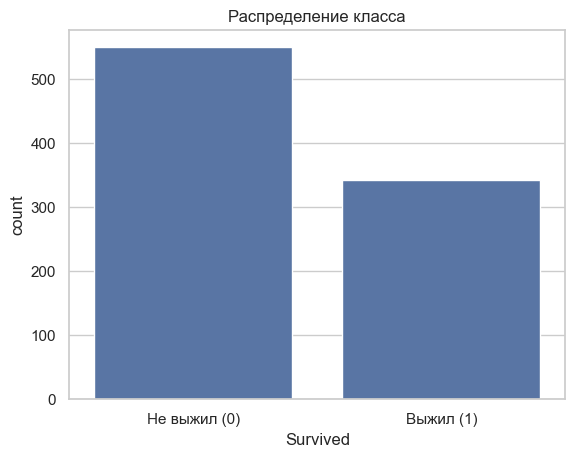

Доля выживших: 0.384


In [40]:
if "Survived" not in df.columns:
    raise ValueError("В датасете отсутствует столбец Survived.")

print("Распределение целевой переменной:")
display(df["Survived"].value_counts().rename(index={0: "Не выжил", 1: "Выжил"}).to_frame("Количество"))

ax = sns.countplot(data=df, x="Survived")
ax.set_xticklabels(["Не выжил (0)", "Выжил (1)"])
ax.set_title("Распределение класса")
ax.set_xlabel("Survived")
plt.show()

print("Доля выживших:", round(df["Survived"].mean(), 3))


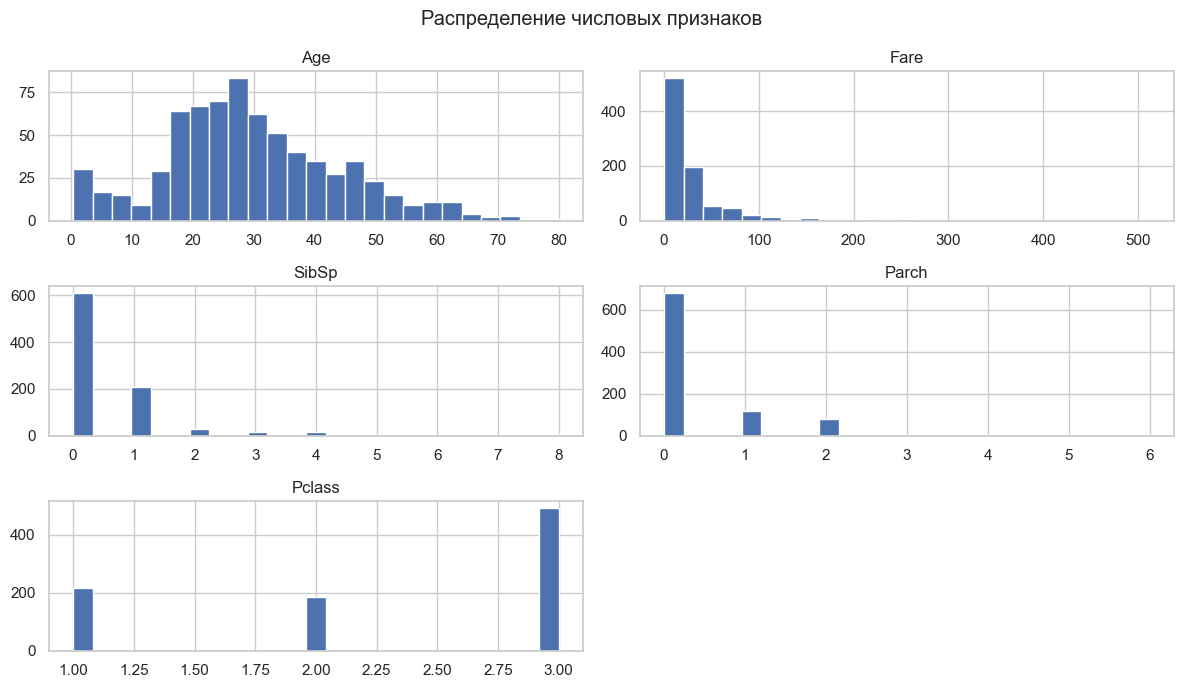

Survived,0,1
Sex,,
female,0.258,0.742
male,0.811,0.189


Survived,0,1
Pclass,,
1,0.370,0.630
2,0.527,0.473
3,0.758,0.242


In [41]:

numeric_for_plot = [c for c in ["Age", "Fare", "SibSp", "Parch", "Pclass"] if c in df.columns]
df[numeric_for_plot].hist(figsize=(12, 7), bins=25)
plt.suptitle("Распределение числовых признаков")
plt.tight_layout()
plt.show()

if "Sex" in df.columns:
    display(pd.crosstab(df["Sex"], df["Survived"], normalize="index").round(3))
if "Pclass" in df.columns:
    display(pd.crosstab(df["Pclass"], df["Survived"], normalize="index").round(3))


### Выводы по первичному анализу

- В `Age`, `Cabin` и `Embarked` обычно встречаются пропуски. Их нельзя просто игнорировать: числовые пропуски буду заполнять медианой.
- `PassengerId`, `Name` и `Ticket` не использую как обычные предикторы: это идентификаторы/строки с большим числом уникальных значений, которые могут приводить к запоминанию отдельных пассажиров.
- `Cabin` также исключу из базовой модели из-за большого количества пропусков и высокой разреженности.
- `Sex`, `Pclass`, `Age`, `Fare`, `SibSp`, `Parch` и `Embarked` имеют потенциальный смысл для задачи. Дополнительно построю `FamilySize` и `IsAlone`.

## 3. Подготовка признаков и разбиение выборки

Создаю признаки размера семьи и одиночного путешествия. Затем делим данные на train и test с сохранением долей классов (`stratify`). Категориальные признаки кодируются One-Hot Encoding, числовые — заполняются медианой. Для SVM и KNN дополнительно применяется StandardScaler.

Все преобразования находятся внутри `Pipeline`/`ColumnTransformer`: `fit` вызывается только на train, поэтому статистики тестовой выборки не попадают в обучение.

In [42]:
data = df.copy()

required_columns = {"Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"}
missing_columns = required_columns - set(data.columns)
if missing_columns:
    raise ValueError(f"В датасете не найдены обязательные столбцы: {missing_columns}")

data = data.dropna(subset=["Survived"]).copy()
data["FamilySize"] = data["SibSp"].fillna(0) + data["Parch"].fillna(0) + 1
data["IsAlone"] = (data["FamilySize"] == 1).astype(int)

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone"]
categorical_features = ["Sex", "Embarked"]

X = data[numeric_features + categorical_features].copy()
y = data["Survived"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("\nДоли классов:")
print("Train:", y_train.value_counts(normalize=True).sort_index().round(3).to_dict())
print("Test: ", y_test.value_counts(normalize=True).sort_index().round(3).to_dict())


Train: (712, 9) Test: (179, 9)

Доли классов:
Train: {0: 0.617, 1: 0.383}
Test:  {0: 0.615, 1: 0.385}


In [43]:
numeric_preprocessor_scaled = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_scaled = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor_scaled, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])

numeric_preprocessor_tree = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

preprocessor_tree = ColumnTransformer(transformers=[
    ("num", numeric_preprocessor_tree, numeric_features),
    ("cat", categorical_preprocessor, categorical_features)
])


**Почему нужно масштабирование?** SVM строит разделяющую границу с учётом расстояний и величины зазора, а KNN непосредственно вычисляет расстояния между объектами. Поэтому признаки с большим числовым диапазоном могут доминировать. Деревья решений, случайный лес и градиентный бустинг используют пороговые разбиения и в стандартном случае не требуют масштабирования.

## 4. Baseline

DummyClassifier всегда предсказывает наиболее частый класс. Это минимальный ориентир: полноценные модели должны заметно превосходить его по F1 для класса выживших.

In [44]:
from sklearn.model_selection import cross_validate, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.metrics import make_scorer, precision_score

# Кросс-валидация на 5 частей
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline = make_pipeline(
    DummyClassifier(strategy="most_frequent")
)

scoring = {
    "Accuracy": "accuracy",
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall": "recall",
    "F1": "f1"
}

base_cv = cross_validate(
    baseline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

display(pd.Series(
    {name: base_cv["test_" + name].mean() for name in scoring},
    name="Dummy CV"
))

baseline.fit(X_train, y_train)

models = {"Dummy": baseline}

Accuracy     0.616576
Precision    0.000000
Recall       0.000000
F1           0.000000
Name: Dummy CV, dtype: float64

## 5. Обучение моделей

Сравниваю пять алгоритмов: Decision Tree, Random Forest, Gradient Boosting, SVM и KNN. Для воспроизводимости фиксирую `random_state` там, где он поддерживается.

In [45]:
models = {
    "Decision Tree": Pipeline([
        ("preprocess", preprocessor_tree),
        ("model", DecisionTreeClassifier(
            max_depth=8, min_samples_leaf=2, class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", preprocessor_tree),
        ("model", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocess", preprocessor_tree),
        ("model", GradientBoostingClassifier(
            n_estimators=200, learning_rate=0.1, max_depth=3,
            random_state=RANDOM_STATE
        ))
    ]),
    "SVM": Pipeline([
        ("preprocess", preprocessor_scaled),
        ("model", SVC(kernel="rbf", C=1.0))
    ]),
    "KNN": Pipeline([
        ("preprocess", preprocessor_scaled),
        ("model", KNeighborsClassifier(n_neighbors=7))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)



## 6. Оценка качества и сравнение

Основная метрика — F1 для класса `Survived = 1`. Также рассчитываем Accuracy, Precision и Recall. Для каждого алгоритма строим confusion matrix.

- **FP (False Positive):** модель предсказала, что пассажир выжил, хотя он не выжил.
- **FN (False Negative):** модель предсказала, что пассажир не выжил, хотя он выжил.

In [46]:
def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0)
    }

all_models = {
    "Dummy baseline": baseline,
    **{name: model for name, model in models.items() if name != "Dummy"}
}
predictions = {}
rows = []

for name, model in all_models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({"Модель": name, **calculate_metrics(y_test, pred)})

results = pd.DataFrame(rows).set_index("Модель").sort_values("F1", ascending=False)
display(results.round(4))

print("Порог лабораторной: F1 > 0.70")
display((results["F1"] > 0.70).rename("F1 > 0.70").to_frame())


,Accuracy,Precision,Recall,F1
Модель,,,,
Decision Tree,0.8156,0.7571,0.7681,0.7626
SVM,0.8212,0.8246,0.6812,0.7460
Random Forest,0.8156,0.8333,0.6522,0.7317
Gradient Boosting,0.8101,0.8070,0.6667,0.7302
KNN,0.7877,0.7385,0.6957,0.7164
Dummy baseline,0.6145,0.0000,0.0000,0.0000


Порог лабораторной: F1 > 0.70


,F1 > 0.70
Модель,
Decision Tree,True
SVM,True
Random Forest,True
Gradient Boosting,True
KNN,True
Dummy baseline,False


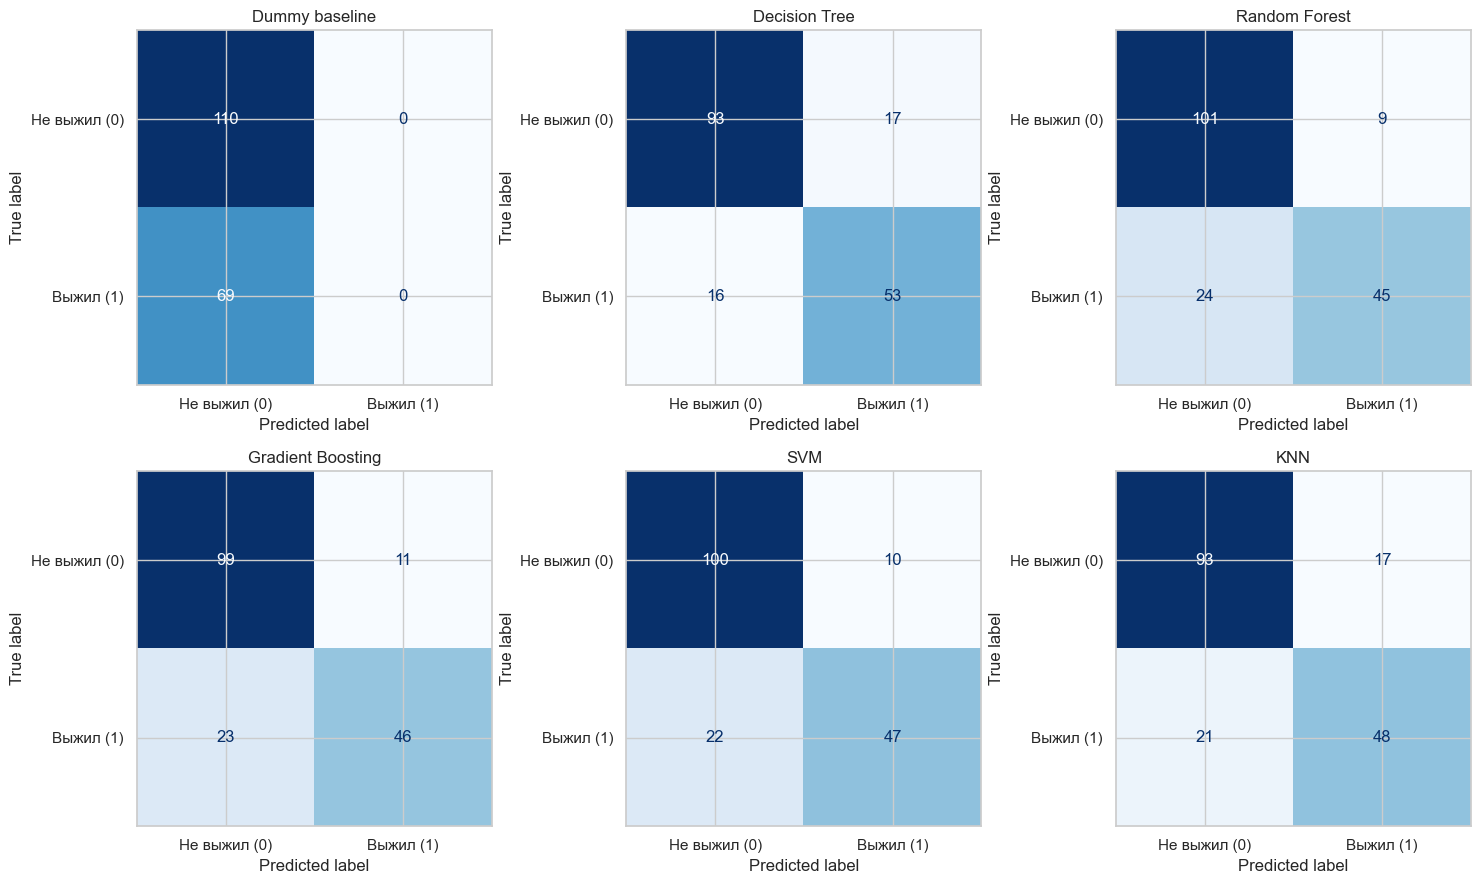

In [47]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

for ax, (name, pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(cm, display_labels=["Не выжил (0)", "Выжил (1)"])
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)

for ax in axes[len(predictions):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


### Интерпретация метрик

Accuracy — доля правильных ответов среди всех пассажиров. Precision показывает, какая доля предсказанных выживших действительно выжила. Recall показывает, какую долю всех реально выживших модель нашла. F1 — гармоническое среднее Precision и Recall.

Для этой задачи FN означает, что реального выжившего пассажира модель отнесла к погибшим; FP — что погибшего пассажира модель ошибочно отнесла к выжившим. Сравнивать модели следует прежде всего по F1, но обязательно учитывать Precision, Recall и матрицы ошибок.

## 7. Decision Tree: переобучение

Сравню качество дерева на обучающей и тестовой выборках. Значительно более высокий результат на train по сравнению с test может указывать на переобучение.

In [48]:
dt = models["Decision Tree"]
dt_train_pred = dt.predict(X_train)
dt_test_pred = predictions["Decision Tree"]

dt_comparison = pd.DataFrame({
    "Train": calculate_metrics(y_train, dt_train_pred),
    "Test": calculate_metrics(y_test, dt_test_pred)
})
display(dt_comparison.round(4))

train_test_gap = dt_comparison.loc["F1", "Train"] - dt_comparison.loc["F1", "Test"]
print(f"Разница F1 (train - test): {train_test_gap:.4f}")
if train_test_gap > 0.10:
    print("Есть заметные признаки переобучения.")
else:
    print("Большого разрыва F1 между train и test не наблюдается.")


,Train,Test
Accuracy,0.8806,0.8156
Precision,0.8310,0.7571
Recall,0.8645,0.7681
F1,0.8474,0.7626


Разница F1 (train - test): 0.0848
Большого разрыва F1 между train и test не наблюдается.


## 8. Feature Importance

Для Decision Tree, Random Forest и Gradient Boosting доступна встроенная важность признаков. Сравню её на исходных признаках после препроцессинга.

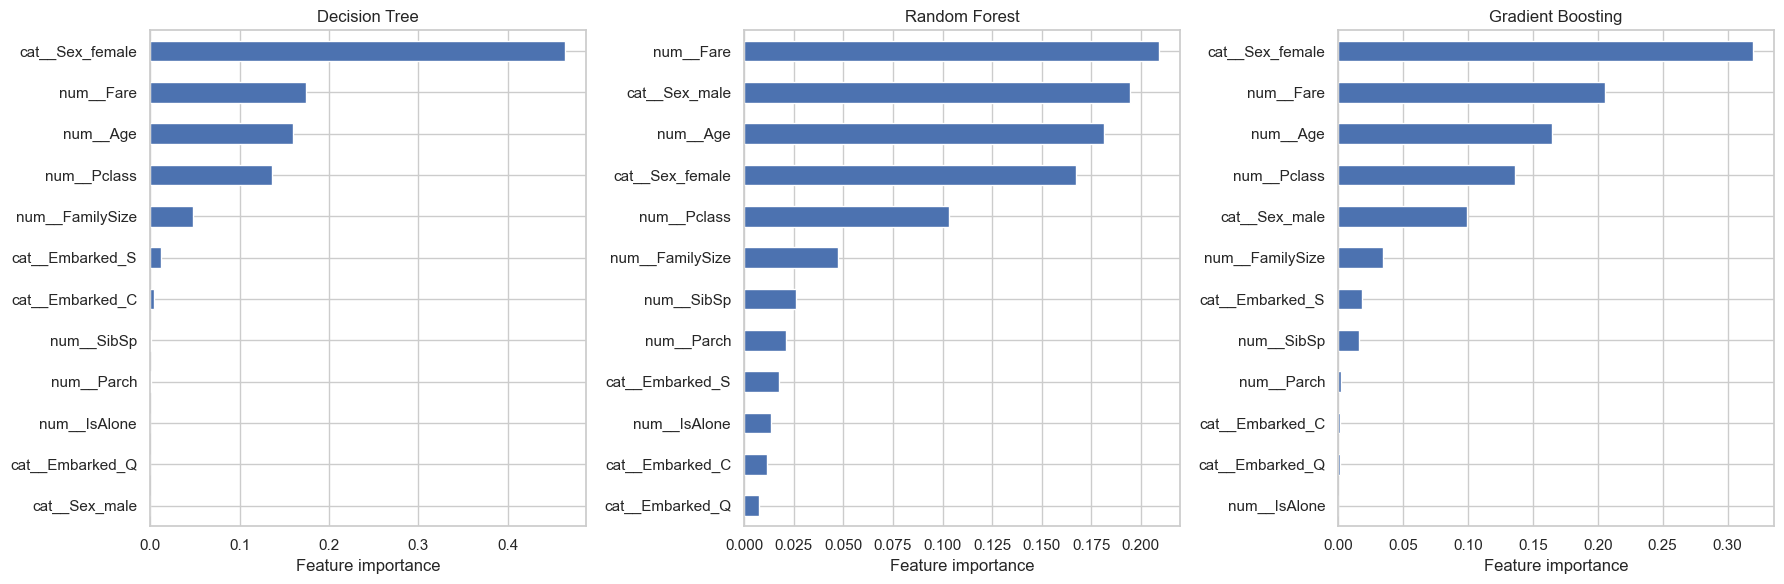

In [49]:
def get_transformed_feature_names(fitted_pipeline):
    prep = fitted_pipeline.named_steps["preprocess"]
    return prep.get_feature_names_out()

tree_model_names = ["Decision Tree", "Random Forest", "Gradient Boosting"]
importance_tables = {}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, name in zip(axes, tree_model_names):
    pipe = models[name]
    estimator = pipe.named_steps["model"]
    names = get_transformed_feature_names(pipe)
    importances = estimator.feature_importances_
    imp = pd.Series(importances, index=names).sort_values(ascending=False)
    importance_tables[name] = imp
    imp.sort_values().plot(kind="barh", ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Feature importance")

plt.tight_layout()
plt.show()


In [50]:
for name, imp in importance_tables.items():
    print("\n", name)
    display(imp.head(10).to_frame("Importance"))



 Decision Tree


,Importance
cat__Sex_female,0.464278
num__Fare,0.173851
num__Age,0.159556
num__Pclass,0.135802
num__FamilySize,0.048178
cat__Embarked_S,0.012172
cat__Embarked_C,0.004472
num__SibSp,0.001031
num__Parch,0.000659
num__IsAlone,0.000000



 Random Forest


,Importance
num__Fare,0.209287
cat__Sex_male,0.194505
num__Age,0.181193
cat__Sex_female,0.167161
num__Pclass,0.103207
num__FamilySize,0.047235
num__SibSp,0.026027
num__Parch,0.021132
cat__Embarked_S,0.017608
num__IsAlone,0.013620



 Gradient Boosting


,Importance
cat__Sex_female,0.319822
num__Fare,0.205925
num__Age,0.164602
num__Pclass,0.135906
cat__Sex_male,0.099477
num__FamilySize,0.034807
cat__Embarked_S,0.018484
num__SibSp,0.015796
num__Parch,0.002171
cat__Embarked_C,0.001618


Встроенная важность показывает, насколько признак помогал конкретной модели уменьшать неоднородность при разбиениях. Она не доказывает, что признак является причиной выживания. Например, признак может быть связан с выживанием через другие обстоятельства или коррелировать с другим признаком. Кроме того, встроенная важность деревьев может быть смещена.

## 9. Анализ ошибок лучшей модели

Выбираю модель с максимальным тестовым F1 и посмотрим, какие пассажиры классифицированы неверно. Тест здесь используется только для анализа уже полученного результата.

In [51]:
best_name = results["F1"].idxmax()
best_model = all_models[best_name]
best_pred = predictions[best_name]

print("Лучшая модель по F1 на тестовой выборке:", best_name)
print(classification_report(y_test, best_pred, target_names=["Не выжил", "Выжил"], zero_division=0))

errors = X_test.copy()
errors["Survived_true"] = y_test
errors["Survived_pred"] = best_pred
errors["Error_type"] = np.where(
    (errors["Survived_true"] == 0) & (errors["Survived_pred"] == 1), "FP",
    np.where((errors["Survived_true"] == 1) & (errors["Survived_pred"] == 0), "FN", "Correct")
)
errors = errors[errors["Error_type"] != "Correct"]
print("Количество ошибок:", len(errors))
display(errors.head(15))


Лучшая модель по F1 на тестовой выборке: Decision Tree
              precision    recall  f1-score   support

    Не выжил       0.85      0.85      0.85       110
       Выжил       0.76      0.77      0.76        69

    accuracy                           0.82       179
   macro avg       0.81      0.81      0.81       179
weighted avg       0.82      0.82      0.82       179

Количество ошибок: 33


,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Sex,Embarked,Survived_true,Survived_pred,Error_type
553,3,22.0,0,0,7.2250,1,1,male,C,1,0,FN
559,3,36.0,1,0,17.4000,2,0,female,S,1,0,FN
536,1,45.0,0,0,26.5500,1,1,male,S,0,1,FP
698,1,49.0,1,1,110.8833,3,0,male,C,0,1,FP
712,1,48.0,1,0,52.0000,2,0,male,S,1,0,FN
455,3,29.0,0,0,7.8958,1,1,male,C,1,0,FN
65,3,NaN,1,1,15.2458,3,0,male,C,1,0,FN
297,1,2.0,1,2,151.5500,4,0,female,S,0,1,FP
564,3,NaN,0,0,8.0500,1,1,female,S,0,1,FP
502,3,NaN,0,0,7.6292,1,1,female,Q,0,1,FP


In [52]:
error_analysis = errors.copy()
error_analysis["Sex"] = error_analysis["Sex"].fillna("Unknown")
error_analysis["Pclass"] = error_analysis["Pclass"].astype(str)

print("Ошибки по полу:")
display(error_analysis.groupby("Sex")["Error_type"].value_counts().unstack(fill_value=0))

print("Ошибки по классу билета:")
display(error_analysis.groupby("Pclass")["Error_type"].value_counts().unstack(fill_value=0))

print("Ошибки по типу:")
display(errors["Error_type"].value_counts().to_frame("Количество"))


Ошибки по полу:


Error_type,FN,FP
Sex,,
female,1,8
male,15,9


Ошибки по классу билета:


Error_type,FN,FP
Pclass,,
1,5,8
2,3,1
3,8,8


Ошибки по типу:


,Количество
Error_type,
FP,17
FN,16


### Возможные причины ошибок

Модель может ошибаться из-за пропусков в возрасте и порту посадки, упрощённого представления семейных связей, отсутствия сведений о конкретных обстоятельствах эвакуации, а также из-за того, что разные пассажиры с похожими значениями признаков могли иметь разные исходы. Несколько ошибочно классифицированных объектов можно изучить в таблице выше.

`PassengerId`, `Name` и `Ticket` исключены из модели, чтобы уменьшить риск запоминания отдельных объектов. Это не гарантирует полного отсутствия всех источников смещения, но делает базовое сравнение более осмысленным.

## 10. Итоговые выводы

В ходе лабораторной работы была решена задача классификации пассажиров Титаника. Были проведены анализ и подготовка данных, обработаны пропуски и категориальные признаки.

Были обучены и сравнены пять моделей: Decision Tree, Random Forest, Gradient Boosting, SVM и KNN. Все модели преодолели установленный порог F1 > 0.70. Лучший результат показала Decision Tree с F1-score = 0.7626.

Также были построены матрицы ошибок, исследована важность признаков и проведён анализ неправильных предсказаний.

В результате были изучены основные этапы решения задачи классификации и достигнута цель лабораторной работы.